# EDA â€” Indonesia IT & Analytics Job Market
Data riil: lowongan IT/data dari Kalibrr + LinkedIn guest API â€” mencakup data/analytics, software engineering, infra, security, QA, IT support, UI/UX, dan ERP/konsultasi.
**Catatan:** data ini bukan sintetis â€” noise dan missingness adalah bagian dari kenyataan data riil.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')
lv = pd.read_csv('../data/processed/lowongan.csv')
sk = pd.read_csv('../data/processed/job_skill.csv')
print(lv.shape, sk.shape)
lv.head()

(1630, 24) (6882, 2)


,id_lowongan,sumber,judul,peran_analyst,peran_it,domain,role_family,senioritas,perusahaan,industri,...,remote,hybrid,fresh_grad_ok,pengalaman,pendidikan,gaji_min_jt,gaji_max_jt,tgl_posting,tgl_tutup,teks
0,kb_271238,kalibrr,Data Analyst,True,False,Data & Analytics,Data Analyst,Mid,Kompas Gramedia,Media Production,...,False,False,True,1–3 thn,S1,NaN,NaN,2026-10-19,2026-11-18,Melakukan analisa kinerja produksi sehingga da...
1,kb_272359,kalibrr,Data Analyst,True,False,Data & Analytics,Data Analyst,Mid,Astro Technologies Indonesia,E-Commerce,...,False,True,False,3–5 thn,S1,NaN,NaN,2026-09-11,2026-11-09,About This Position We are looking for a Data ...
2,kb_207492,kalibrr,Big Data Analyst,True,False,Data & Analytics,Data Engineer,Mid,Kompas Gramedia,Media Production,...,False,False,False,3–5 thn,S1,NaN,10.0,2026-10-20,2026-11-29,Investigate questions that span qualitative te...
3,kb_270033,kalibrr,Data Analyst,True,False,Data & Analytics,Data Analyst,Mid,PT BFI Finance Indonesia Tbk,Financial Services,...,False,False,False,3–5 thn,S1,NaN,NaN,2026-09-03,2026-11-14,"Mengumpulkan, membersihkan, dan menganalisis d..."
4,kb_267421,kalibrr,Digital Business Data Analyst,True,False,Data & Analytics,Data Analyst,Senior / Lead,PT BFI Finance Indonesia Tbk,Financial Services,...,False,False,False,5–10 thn,S1,NaN,NaN,2026-10-02,2026-11-29,Partner with product teams to defince and trac...


## Komposisi domain, peran & sumber

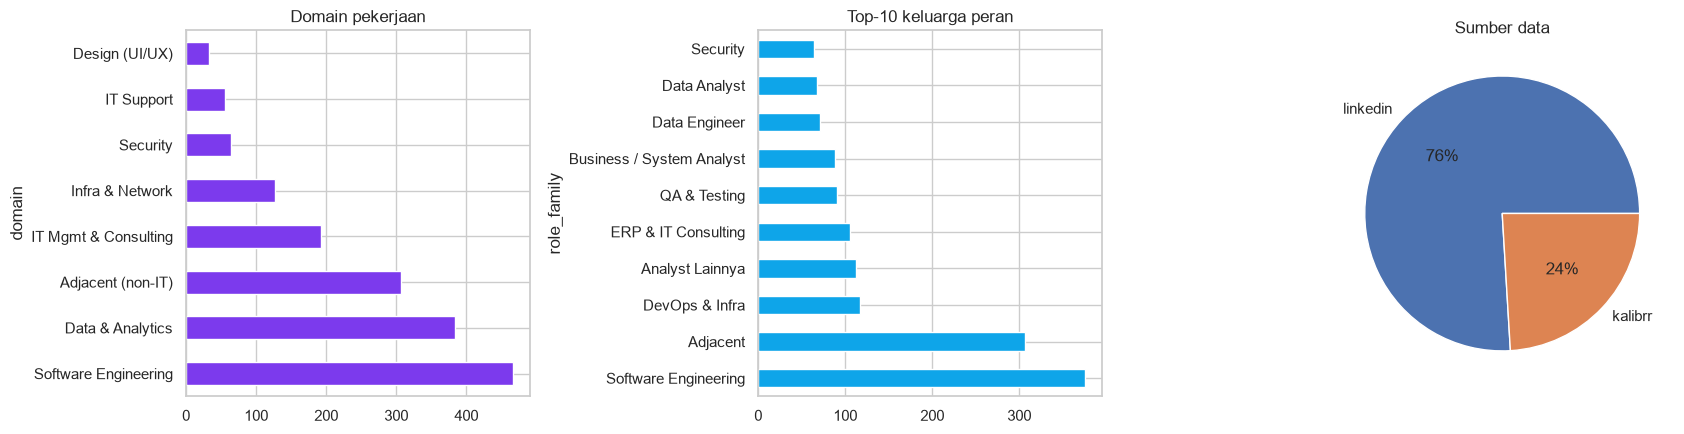

In [2]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
lv.domain.value_counts().plot.barh(ax=ax[0], color='#7C3AED')
ax[0].set_title('Domain pekerjaan')
lv.role_family.value_counts().head(10).plot.barh(ax=ax[1], color='#0EA5E9')
ax[1].set_title('Top-10 keluarga peran')
lv.sumber.value_counts().plot.pie(ax=ax[2], autopct='%.0f%%')
ax[2].set_ylabel(''); ax[2].set_title('Sumber data')
plt.tight_layout()

## Skill demand â€” apa yang benar-benar diminta pasar?

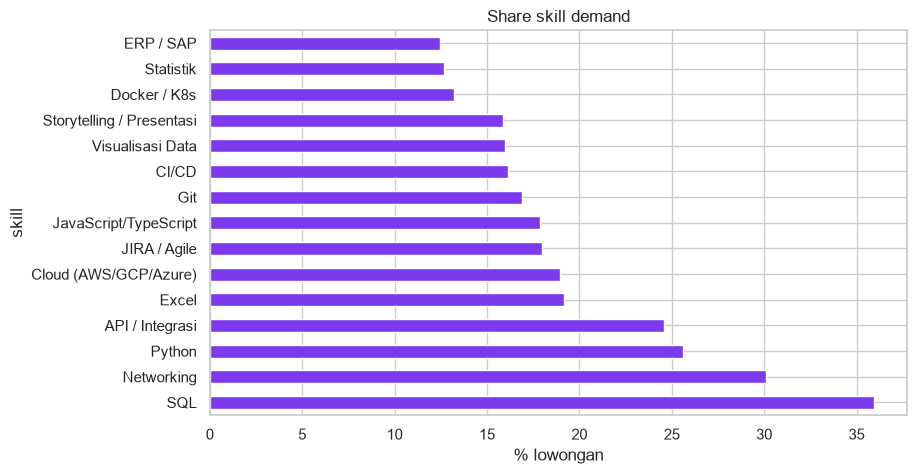

skill
SQL                          586
Networking                   491
Python                       417
API / Integrasi              401
Excel                        312
Cloud (AWS/GCP/Azure)        309
JIRA / Agile                 293
JavaScript/TypeScript        291
Git                          275
CI/CD                        263
Visualisasi Data             260
Storytelling / Presentasi    259
Docker / K8s                 215
Statistik                    207
ERP / SAP                    203
Name: count, dtype: int64


In [3]:
n = len(lv)
top = sk.skill.value_counts().head(15)
(top / n * 100).plot.barh(color='#7C3AED', figsize=(9, 5))
plt.xlabel('% lowongan'); plt.title('Share skill demand')
plt.show()
print(top)

## Skill signature per domain
Top-3 skill per domain â€” menunjukkan bedanya tuntutan tiap segmen IT.

In [4]:
sig = (sk.merge(lv[['id_lowongan','domain']], on='id_lowongan')
         .groupby(['domain','skill']).size().rename('n')
         .reset_index()
         .sort_values(['domain','n'], ascending=[True,False])
         .groupby('domain').head(3))
print(sig.to_string(index=False))

              domain                     skill   n
   Adjacent (non-IT)                Networking 184
   Adjacent (non-IT)                     Excel 128
   Adjacent (non-IT) Storytelling / Presentasi 128
    Data & Analytics                       SQL 220
    Data & Analytics                    Python 183
    Data & Analytics                 Statistik 155
      Design (UI/UX)       Figma / Design Tool  30
      Design (UI/UX)                Networking  10
      Design (UI/UX)     JavaScript/TypeScript   5
IT Mgmt & Consulting                 ERP / SAP 105
IT Mgmt & Consulting              JIRA / Agile  55
IT Mgmt & Consulting                       SQL  45
          IT Support                Networking  21
          IT Support                     Linux   9
          IT Support              JIRA / Agile   7
     Infra & Network     Cloud (AWS/GCP/Azure)  69
     Infra & Network                Networking  67
     Infra & Network              Docker / K8s  61
            Security           

## Geografi & cara kerja

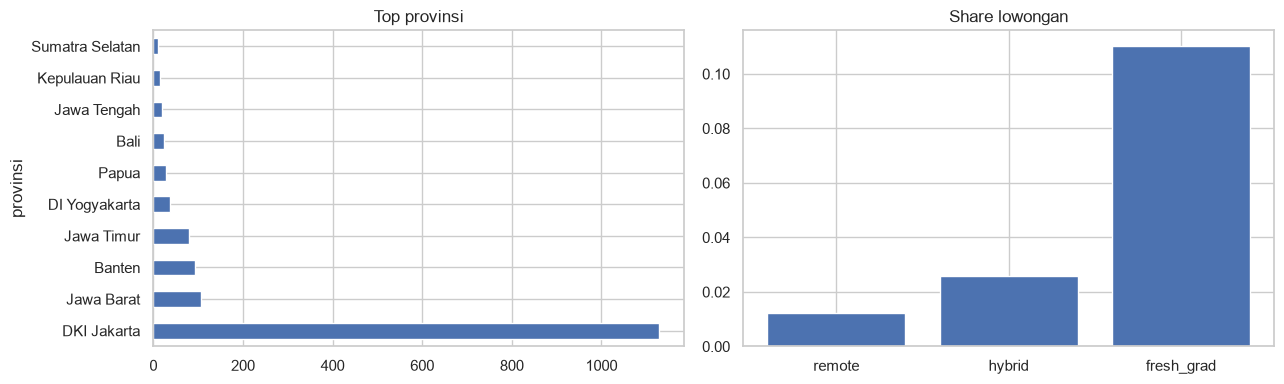

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
lv.provinsi.value_counts().head(10).plot.barh(ax=ax[0])
ax[0].set_title('Top provinsi')
ax[1].bar(['remote', 'hybrid', 'fresh_grad'],
          [lv.remote.mean(), lv.hybrid.mean(), lv.fresh_grad_ok.mean()])
ax[1].set_title('Share lowongan'); plt.tight_layout()

## Gaji â€” analisis terbatas pada lowongan transparan
Hanya ~3% lowongan menampilkan gaji â€” coverage sangat bias.

49/1630 lowongan bergaji


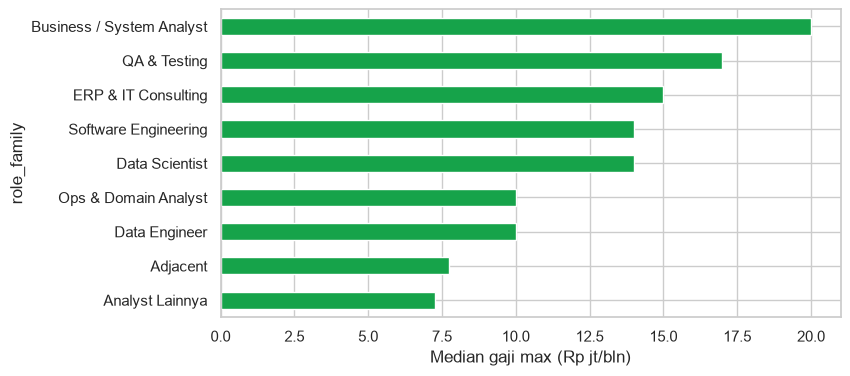

In [6]:
bg = lv.dropna(subset=['gaji_max_jt'])
print(f'{len(bg)}/{len(lv)} lowongan bergaji')
(bg.groupby('role_family').gaji_max_jt.median().sort_values()
   .plot.barh(figsize=(8,4), color='#16A34A'))
plt.xlabel('Median gaji max (Rp jt/bln)'); plt.show()

## Insight utama
1. Pasar IT/data RI terkonsentrasi ekstrem di DKI Jakarta.
2. Software Engineering = segmen terbesar; Data & Analytics masih terbesar kedua â€” dua dunia dengan skill signature beda.
3. Dua platform, dua pasar: Kalibrr=UKM/lokal, LinkedIn=enterprise/multinasional.
4. Remote murni langka â€” hybrid mulai muncul tapi minoritas.
5. Transparansi gaji sangat rendah: analisis gaji bias.
6. Search job board noisy: hanya sebagian hasil benar-benar relevan â€” filtering adalah bagian inti pipeline.